# IND320 Project Work, Part 3 - Data quality

GitHub: [IND320-kahaland](https://github.com/kahalandkh/IND320-kahaland) \
Streamlit: [IND320 Energy Project](https://ind320-kahaland-vqqy43wgawwsxmytoyb9ah.streamlit.app)

## 0. Setup and imports

In [1]:
import sys

from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openmeteo_requests
import requests_cache
from retry_requests import retry

from modules.weather import download_weather


## 1. Geographical Data and Random Sampling

### 1.1 Retrieve geographical data from NVE

I downloaded two shapefiles from [NVE Atlas](https://atlas.nve.no/): **Budområder**, which covers the five electricity areas (NO1-NO5), and **NVE_Region**, which consists of five regions (RV, RØ, RS, RM and RN). The NVE regions will be used to represent the VASS areas in Magasinstatistikk. According to the assignment text, East is split into RS and RØ, and North into RM and RN, so these regions need to be combined.

The shapefiles are saved in the `data/geographical/` folder in the project.


#### 1.1.1 Inspect geographical data

The shapefiles are loaded using GeoPandas. I first check the region identifiers and coordinate reference systems (CRS) before working with the geometries. I also plot both datasets to check the geographical boundaries before combining the NVE regions.

In [2]:
# Load the geographical datasets from NVE
budomrader = gpd.read_file("../data/geographical/Budområder/Budområder.shp", encoding="utf-8")
nve_regions = gpd.read_file("../data/geographical/NVE_Region/NVE_Region.shp", encoding="utf-8")

In [3]:
# Check region identifiers and coordinate reference systems
print("Budområder:")
display(budomrader[["budomr"]])
print("CRS:", budomrader.crs)

print("\nNVE regions:")
display(nve_regions[["REGION", "REGIONNAVN"]])
print("CRS:", nve_regions.crs)

Budområder:


,budomr
0,NO 1
1,NO 2
2,NO 3
3,NO 4
4,NO 5


CRS: EPSG:25833

NVE regions:


,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


CRS: EPSG:25833


Both datasets contain five regions and use EPSG:25833 (ETRS89 / UTM zone 33N). The electricity area identifiers in the shapefile include spaces (e.g. `NO 3` instead of `NO3`). I'll account for this when working with the region identifiers later.

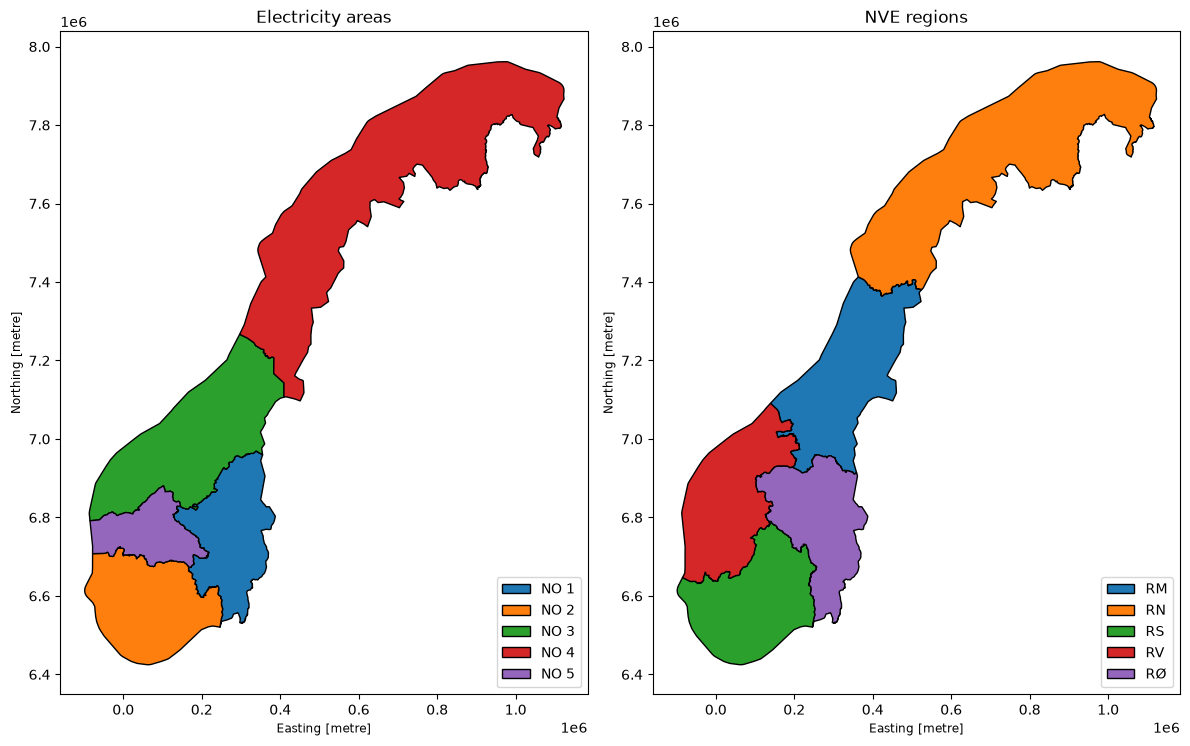

In [4]:
# Plot the electricity areas and NVE regions
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

budomrader.plot(ax=axes[0], column="budomr", legend=True, legend_kwds={"loc": "lower right"}, edgecolor="black")
axes[0].set_title("Electricity areas")

nve_regions.plot(ax=axes[1], column="REGION", legend=True, legend_kwds={"loc": "lower right"}, edgecolor="black")
axes[1].set_title("NVE regions")

plt.tight_layout()
plt.show()

#### 1.1.2 Combine NVE regions

[NVE](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/) provides a map showing the three vassmagasinområder used in Magasinstatistikk. Based on this map, the plot above and the assignment instructions, I use the following combinations of NVE regions to represent the VASS areas:

1. **VASS1:** RS + RØ
2. **VASS2:** RV
3. **VASS3:** RM + RN

In [5]:
# Map the five NVE regions to the three VASS areas
region_to_vass = {"RS": "VASS1",
                  "RØ": "VASS1",
                  "RV": "VASS2",
                  "RM": "VASS3",
                  "RN": "VASS3"}

# Assign VASS identifiers without modifying the original GeoDataFrame
nve_vass = nve_regions[["REGION", "geometry"]].copy()
nve_vass["VASS"] = nve_vass["REGION"].map(region_to_vass)

# Merge geometries belonging to the same VASS area
vass_regions = nve_vass[["VASS", "geometry"]].dissolve(by="VASS", as_index=False)
display(vass_regions[["VASS"]])

,VASS
0,VASS1
1,VASS2
2,VASS3


### 1.2 Random sampling

I use GeoPandas to generate 1 000 random locations within each electricity area and VASS area. A fixed random seed is used to make the sampling reproducible. The coordinates are then converted from EPSG:25833 to WGS84 (EPSG:4326) for use with Open-Meteo.

In [6]:
# Generate 1000 random points within each region
K = 1000
rng = 26102025

bud_points = budomrader[["budomr", "geometry"]].copy()
bud_points["geometry"] = bud_points.geometry.sample_points(size=K, rng=rng)
bud_points = bud_points.explode(ignore_index=True)

vass_points = vass_regions[["VASS", "geometry"]].copy()
vass_points["geometry"] = vass_points.geometry.sample_points(size=K, rng=rng)
vass_points = vass_points.explode(ignore_index=True)

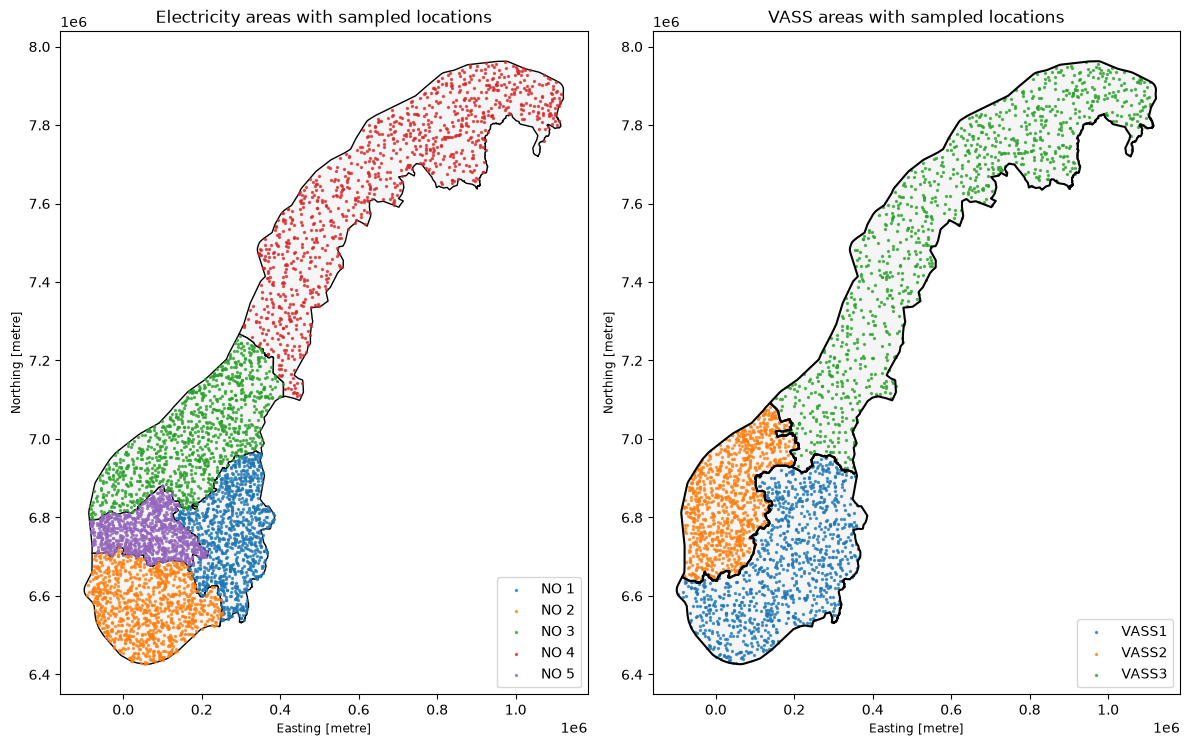

In [7]:
# Plot the sampled locations in each region
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

budomrader.plot(ax=axes[0], color="whitesmoke", edgecolor="black")
bud_points.plot(ax=axes[0], column="budomr", categorical=True, legend=True, legend_kwds={"loc": "lower right"}, markersize=2, alpha=0.7)
axes[0].set_title("Electricity areas with sampled locations")

vass_regions.plot(ax=axes[1], color="whitesmoke", edgecolor="none")
vass_regions.geometry.exterior.plot(ax=axes[1], color="black")
vass_points.plot(ax=axes[1], column="VASS", categorical=True, legend=True, legend_kwds={"loc": "lower right"}, markersize=2, alpha=0.7)
axes[1].set_title("VASS areas with sampled locations")

plt.tight_layout()
plt.show()

In [8]:
# Convert sampled locations to WGS84 (EPSG:4326) for Open-Meteo
bud_points_wgs84 = bud_points.to_crs(epsg=4326)
vass_points_wgs84 = vass_points.to_crs(epsg=4326)

# Extract latitude and longitude
for points in [bud_points_wgs84, vass_points_wgs84]:
    points["latitude"] = points.geometry.y
    points["longitude"] = points.geometry.x

# Display a few coordinates from each dataset
display(bud_points_wgs84[["budomr", "latitude", "longitude"]].head())
display(vass_points_wgs84[["VASS", "latitude", "longitude"]].head())

,budomr,latitude,longitude
0,NO 1,61.659500,10.105636
1,NO 1,60.527092,9.653369
2,NO 1,60.845997,9.488886
3,NO 1,61.494991,11.897735
4,NO 1,60.579663,9.776923


,VASS,latitude,longitude
0,VASS1,61.559486,10.263349
1,VASS1,59.853085,7.942125
2,VASS1,62.441307,10.575522
3,VASS1,61.568552,8.892610
4,VASS1,62.069754,8.110503


In [9]:
# Prepare sampled coordinates for weather downloads
bud_locations = bud_points_wgs84[["budomr", "longitude", "latitude"]].rename(columns={"budomr": "region"})

vass_locations = vass_points_wgs84[["VASS", "longitude", "latitude"]].rename(columns={"VASS": "region"})

# Use consistent region identifiers (e.g. "NO3" instead of "NO 3")
bud_locations["region"] = bud_locations["region"].str.replace(" ", "")

weather_locations = pd.concat([bud_locations, vass_locations], ignore_index=True)

# Save coordinates for reuse in Streamlit without overwriting the existing file
locations_file = Path("../data/geographical/weather_locations.csv")

if not locations_file.exists():
    weather_locations.to_csv(locations_file, index=False)
    print(f"Saved {len(weather_locations)} locations to {locations_file}")
else:
    print(f"File already exists: {locations_file}")

File already exists: ../data/geographical/weather_locations.csv


## 2. Historical Weather Data from Open-Meteo

### 2.1 Single-location API request

The Open-Meteo API is first tested using one of the sampled locations in `NO3`. The request retrieves hourly temperature and precipitation data for 2024 using the ERA5 reanalysis model. The response is used to check the returned data and timestamps before extending the download to entire regions.

The code is based on the Python example generated in the [Open-Meteo Historical Weather API documentation](https://open-meteo.com/en/docs/historical-weather-api).

In [10]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Select one of the sampled locations in NO3
no3_points = bud_points_wgs84[bud_points_wgs84["budomr"] == "NO 3"]
example_point = no3_points.iloc[0]

# The order of variables in hourly or daily is important to assign them correctly below
url = "https://archive-api.open-meteo.com/v1/archive"
params = {"latitude": float(example_point["latitude"]),
          "longitude": float(example_point["longitude"]),
          "start_date": "2024-01-01",
          "end_date": "2024-12-31",
          "hourly": ["temperature_2m", "precipitation"],
          "models": "era5",
          "timezone": "Europe/Berlin",
          "timeformat": "unixtime"}  # Allows DST-aware conversion using the named time zone
responses = openmeteo.weather_api(url, params=params)

# Process the response for the selected location
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone: {response.Timezone().decode()} ({response.TimezoneAbbreviation().decode()})")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()

# Convert Unix timestamps from UTC to local time, accounting for daylight saving time
# The reported UtcOffsetSeconds() is fixed and is not used for this conversion
hourly_data = {"date": pd.date_range(start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                                     end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                                     freq=pd.Timedelta(seconds=hourly.Interval()),
                                     inclusive="left").tz_convert(response.Timezone().decode())}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["precipitation"] = hourly_precipitation

hourly_dataframe = pd.DataFrame(data=hourly_data)
print("\nHourly data\n", hourly_dataframe)

# Check the number of observations and the returned local date range
print(f"\nNumber of observations: {len(hourly_dataframe)}")
print(f"First timestamp: {hourly_dataframe['date'].iloc[0]}")
print(f"Last timestamp: {hourly_dataframe['date'].iloc[-1]}")

# Check the DST transition on 27 October 2024, when 02:00 occurs twice
oct_27 = hourly_dataframe.loc[hourly_dataframe["date"].dt.strftime("%Y-%m-%d") == "2024-10-27", "date"]

print(f"\nHours on 27 October 2024: {len(oct_27)}")
print("Timestamps at 02:00:")
for timestamp in oct_27[oct_27.dt.hour == 2]:
    print(timestamp)

Coordinates: 64.0°N 8.75°E
Elevation: 0.0 m asl
Timezone: Europe/Berlin (GMT+1)
Timezone difference to GMT+0: 3600s

Hourly data
                           date  temperature_2m  precipitation
0    2024-01-01 00:00:00+01:00            0.05            0.0
1    2024-01-01 01:00:00+01:00            0.00            0.0
2    2024-01-01 02:00:00+01:00            0.00            0.0
3    2024-01-01 03:00:00+01:00            0.05            0.0
4    2024-01-01 04:00:00+01:00            0.10            0.0
...                        ...             ...            ...
8779 2024-12-31 19:00:00+01:00            0.90            0.1
8780 2024-12-31 20:00:00+01:00            1.05            0.1
8781 2024-12-31 21:00:00+01:00            1.15            0.0
8782 2024-12-31 22:00:00+01:00            1.30            0.1
8783 2024-12-31 23:00:00+01:00            1.30            0.2

[8784 rows x 3 columns]

Number of observations: 8784
First timestamp: 2024-01-01 00:00:00+01:00
Last timestamp: 2024-12-31 2

The API returned 8 784 hourly observations for 2024. The time zone conversion also handles the transition from summer to winter time on 27 October, when 02:00 occurs twice with different UTC offsets.

### 2.2 Regional weather data download

The sampled coordinates from Section 1 are used to retrieve hourly ERA5 weather data for a selected region and time interval. The coordinates are divided into batches of 100 to avoid excessively long API request URLs.

In [11]:
!cat ../modules/weather.py


import pandas as pd
import openmeteo_requests
import requests_cache
from retry_requests import retry


# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession(".cache", expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)


def download_weather(region, start_date, end_date, locations, batch_size=100, verbose=False):
    """
    Download hourly ERA5 weather data for a selected region and time interval.

    The sampled locations are downloaded in batches. Returns the requested
    coordinates and their corresponding Open-Meteo API responses.
    """
    region = region.upper().replace(" ", "")

    if batch_size < 1:
        raise ValueError("batch_size must be at least 1")

    if pd.Timestamp(start_date) > pd.Timestamp(end_date):
        raise ValueError("start_date must not be after end_date")

    # Select the sampled coordinates for the 

In [12]:
coordinates, responses = download_weather(region="NO3", start_date="2024-01-01", end_date="2024-12-31", locations=weather_locations, verbose=True, batch_size=100)

print(f"Requested locations: {len(coordinates)}")
print(f"API responses: {len(responses)}")

Downloaded 100/1000 locations
Downloaded 200/1000 locations
Downloaded 300/1000 locations
Downloaded 400/1000 locations
Downloaded 500/1000 locations
Downloaded 600/1000 locations
Downloaded 700/1000 locations
Downloaded 800/1000 locations
Downloaded 900/1000 locations
Downloaded 1000/1000 locations
Requested locations: 1000
API responses: 1000


<div style="background-color:#EAF2F7; border-left:5px solid #3E7FA6; padding:12px 16px; border-radius:6px;">

<h2>AI usage</h2>

To be filled out...

</div>

## Project log

I downloaded the Budområder and NVE_Region shapefiles from NVE Atlas and used GeoPandas to combine the NVE regions into three VASS areas. For each region, 1 000 random locations were generated using a fixed random seed. The coordinates were then converted to WGS84 for use with Open-Meteo and saved to a CSV file so the same locations can be used later in the Streamlit app.

For the weather data, I wrote a function to download hourly ERA5 temperature and precipitation for a selected region and time interval. The coordinates are sent in batches of 100 to avoid overly long API request URLs. While downloading data for NO3 for 2024, I ran into Open-Meteo's rate limit. To avoid starting over after hitting the limit, I used a local cache so that successful API responses can be reused when continuing the download.


To be filled out...